# isomorfismos

In [24]:
trait Iso[A, B]{
    def from(a: A): B 
    def to(b: B): A
}

defined trait Iso

In [3]:
object Iso extends Iso[List[Unit], Int]{

    def from(a: List[Unit]): Int = 
        a.length

    def to(b: Int): List[Unit] = 
        if (b == 0) Nil
        else () :: to(b-1)

}

defined object Iso

In [5]:
def from[A, B, C](f: A => B): (B => C) => (A => C) = 
    g => a => g(f(a) : B) : C

def to[A, B, C](f: [C] => (B => C) => (A => C)): A => B = 
    f[B](identity)

defined function from
defined function to

defined function from

In [2]:
def from[A, B](f: A => B): [R] => A => (B => R) => R = 
    [r] => (a: A) => (g: B => r) => g(f(a))

def to[A, B](f: [R] => A => (B => R) => R): A => B = 
    a => f[B](a)(identity)

defined function from
defined function to

logaritmos and representability

Log (f × g) ' Log f + Log g

Log (f · g) ' Log f × Log g

# curry-howard

In [1]:
type Not[A] = A => Nothing

defined type Not

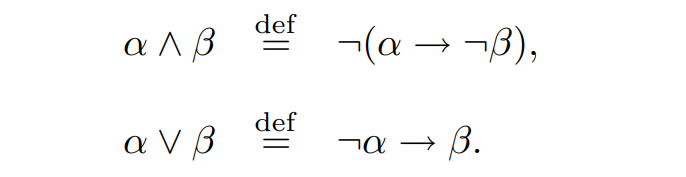

In [2]:
def proof[A, B](p1: (A, B)): Not[A => Not[B]] = 
    f => f(p1._1)(p1._2)

defined function proof

In [11]:
def proof[A, B](dn: Not[Not[A]] => A)(p1: Not[A => Not[B]]): (A, B) = 
    (dn((na: Not[A]) => p1((a: A) => (b: B) => na(a))), 
     p1((a: A) => (b: B) => ???)

In [16]:
def proof[A, B](dn: [t] => Not[Not[t]] => t)(ab: Not[A => Not[B]]): A = 
    dn[A]((na: Not[A]) => ab((a: A) => (b: B) => na(a)))
    

defined function proof

In [17]:
def proof[A, B](dn: [t] => Not[Not[t]] => t)(ab: Not[A => Not[B]]): B = 
    dn[B]((nb: Not[B]) => ab((a: A) => (b: B) => nb(b)))
    

defined function proof

In [18]:
def proof[A, B](C: [t] => Not[Not[t]] => t)(M: Not[A => Not[B]]): B = 
    C((j: Not[B]) => M((a: A) => (b: B) => j(b)))

defined function proof

In [36]:
type And[A, B] = [C] => (A => B => C) => C
def _1[A, B](and: And[A, B]): A = and[A]((a: A) => (b: B) => a)
def _2[A, B](and: And[A, B]): B = and[B]((a: A) => (b: B) => b)

type And1[A, B] = (A => B => Nothing) => Nothing
def _1_[A, B](and: And1[A, B])(dn: Not[Not[A]] => A): A = dn(na => and((a: A) => (b: B) => na(a)))
def _2_[A, B](and: And1[A, B])(dn: Not[Not[B]] => B): B = dn(nb => and((a: A) => (b: B) => nb(b)))

defined type And
defined function _1
defined function _2
defined type And1
defined function _1_
defined function _2_

In [38]:
class IsoAnd[A, B](dn: [t] => Not[Not[t]] => t) extends Iso[And[A, B], And1[A, B]]{
    
    def from(and: And[A, B]): And1[A, B] =
        f => f(_1(and))(_2(and))
    
    def to(and: And1[A, B]): And[A, B]=
        [t] => (f: A => B => t) => f(_1_(and)(dn[A]))(_2_(and)(dn[B]))
}

defined class IsoAnd

In [40]:
class IsoAnd[A, B](dn: [t] => Not[Not[t]] => t) extends Iso[(A, B), And1[A, B]]{
    
    def from(and: (A, B)): And1[A, B] =
        f => f(and._1)(and._2)
    
    def to(and: And1[A, B]): (A, B) =
        (_1_(and)(dn[A]), _2_(and)(dn[B]))
}

defined class IsoAnd

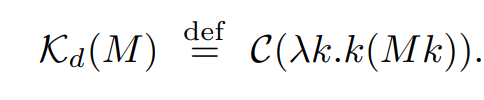
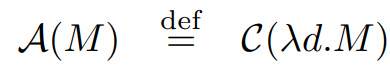

In [47]:
trait Control{
    
    val C: [t] => Not[Not[t]] => t
    
    val A: [t] => Nothing => t = 
        [t] => (M: Nothing) => C[t](_ => M)
    
    val K: [t] => (Not[t] => t) => t = 
        [t] => (M: Not[t] => t) => C[t](k => k(M(k)))
}

defined trait Control

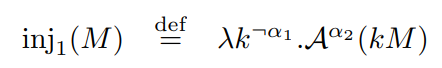
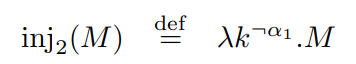
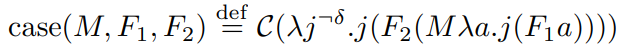

In [61]:
type Or[A, B] = Not[A] => B

object Or{
    def inj1[A, B](a: A): Not[A] => B = 
        na => na(a)
    
    def inj1_[A1, A2](M: A1)(A: [t] => Nothing => t): Not[A1] => A2 = 
        k => A[A2](k(M))

    def inj2[A, B](b: B): Not[B] => B = 
        _ => b
    
    def caseOr[A1, A2, B](
            F1: A1 => B, 
            F2: A2 => B)(
            C: [t] => Not[Not[t]] => t): 
            A1 Or A2 => B = 
        (M: Not[A1] => A2) => 
            C[B](j => j(F2(M(a => j(F1(a))))))
}

defined type Or
defined object Or

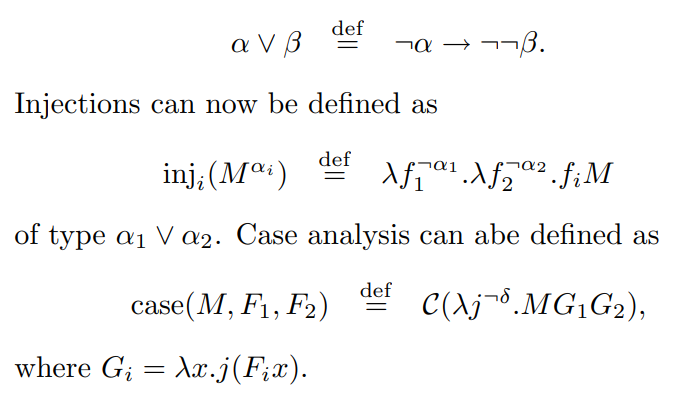

In [69]:
    def caseOr[A1, A2, B](
            F1: A1 => B, 
            F2: A2 => B)(
            C: [t] => Not[Not[t]] => t): 
            (Not[A1] => Not[Not[A2]]) => B = 
        (M: Not[A1] => Not[Not[A2]]) => 
            // C[B](j=> j(F2(C[A2](M(a => j(F1(a)))))))
            C[B](j => M(a1 => j(F1(a1)))(a2 => j(F2(a2))))

defined function caseOr

# ADTs

In [3]:
extension [A, B](t: Either[A, B])

    def updateLeft[C](f: A => C): Either[C, B] = 
        t match 
            case Left(a) => Left(f(a))
            case Right(b) => Right(b)

    def updateRight[C](f: B => C): Either[A, C] = 
        t match 
            case Left(a) => Left(a)
            case Right(b) => Right(f(b))

defined extension methods 

In [10]:
extension [A, B](t: (A, B))
    def update1[C](f: A => C): (C, B) = 
        (f(t._1), t._2)
    def update2[C](f: B => C): (A, C) = 
        (t._1, f(t._2))

defined extension methods 

In [1]:
sealed trait Binary
case class Unit() extends Binary
case class Twice(b: Binary) extends Binary
case class TwicePlus1(b: Binary) extends Binary

object Binary{
    def toInt(b: Binary): Int = 
        b match {
            case Unit() => 0
            case Twice(b) => toInt(b)*2
            case TwicePlus1(b) => toInt(b)*2 + 1
        }
    
    val _0: Binary = Unit()
    val _1: Binary = TwicePlus1(_0)
    val _2: Binary = Twice(_1)
    val _3: Binary = TwicePlus1(_1)
    val _4: Binary = Twice(_2)
    val _5: Binary = TwicePlus1(_2)
    val _6: Binary = Twice(_3)
}

defined trait Binary
defined class Unit
defined class Twice
defined class TwicePlus1
defined object Binary

# Funciones

composición generalizada

In [4]:
def compose[A, B, C, D, E](g: (C, D) => E, f1: A => C, g2: B => D): (A, B) => E = 
    ???

defined function compose

# Listas


In [1]:
def diff[A](l1: List[A])(l2: List[A]): List[A] = 
    l1 match 
        case Nil => Nil
        case h :: t if l2.contains(h) => diff(t)(l2.diff(List(h)))
        case h :: t => h :: diff(t)(l2.diff(List(h)))

defined function diff

In [2]:
def diff[A](l1: List[A])(l2: List[A]): List[A] = 
    l1.foldRight((l2, List[A]())): 
        case (h, (l2, sol)) => 
            (l2.diff(List(h)), if l2.contains(h) then sol else h :: sol)
    ._2

defined function diff

# Árboles

In [2]:
sealed trait Tree[A]
case class Tip[A](a: A) extends Tree[A]
case class Branch[A](l: Tree[A], r: Tree[A]) extends Tree[A]

defined trait Tree
defined class Tip
defined class Branch

In [3]:
def flatten_r[A](t: List[Tree[A]])(k: List[A]): List[A] = 
    t match {
        case Nil => 
            k
        case Tip(a) :: tail => 
            flatten_r(tail)(a :: k)
        case Branch(l, r) :: tail => 
            flatten_r(r :: l :: tail)(k)
    }

def flatten[A](t: Tree[A]): List[A] = 
    flatten_r(List(t))(Nil)

defined function flatten_r
defined function flatten